### Main notebook for CCF data ($\tau_{max, }v_{pol}$) visualization.

In [3]:
import sys
import os
import re
import flap
import flap_w7x_abes
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import h5py
import json

CORR_THRESHOLD = 0.35

mpl.rcParams.update({
    'font.size': 12
})

with open('../lcfs_pos.json', 'r') as f:
    lcfs_pos = json.load(f)

In [4]:
exp_id = '20250409.046'
r_lcfs = lcfs_pos[exp_id]
r_lcfs

6.25

In [5]:
i_tor = flap.load(f'../plasma_param_data/{exp_id}/{exp_id}_itor.pkl')
p_ecrh = flap.load(f'../plasma_param_data/{exp_id}/{exp_id}_ecrh.pkl')
w_dia = flap.load(f'../plasma_param_data/{exp_id}/{exp_id}_wdia.pkl')
n_int = flap.load(f'../plasma_param_data/{exp_id}/{exp_id}_lineint.pkl')

In [6]:
with h5py.File(f'../processed_data/{exp_id}/{exp_id}_elliptical.h5', 'r') as f:
    
    exp_id = f['ccf_data'].attrs['exp_id']
    udefl = f['ccf_data'].attrs['poloidal_deflection_voltage']
    deltay = f['ccf_data'].attrs['poloidal_separation']
    twindow = f['ccf_data'].attrs['ccf_window']
    intervaln = f['ccf_data'].attrs['ccf_interval_n']
    
    times = f['ccf_data/time_range'][:]
    channels = f['ccf_data/channels'][:]
    
    tau = f['ccf_data/ccf_max_time_lags'][:]
    corrs = f['ccf_data/ccf_correlations'][:]
    vpol = f['ccf_data/poloidal_velocity'][:]
    vpol_err = f['ccf_data/poloidal_velocity_err'][:]

In [7]:
spatcal = flap_w7x_abes.ShotSpatCal('20250409.046')
spatcal.read()
dev_r = np.array([
    spatcal.data['Device R'][spatcal.data['Channel name'] == f'ABES-{ch}'] for ch in np.arange(1, 41)
]).T[0]

In [8]:
min(dev_r), max(dev_r)

(np.float64(6.086611510145259), np.float64(6.305569997775299))

In [9]:
vpol_filtered = vpol.copy()
vpol_err_filtered = vpol_err.copy()
vpol_filtered[corrs < CORR_THRESHOLD] = np.nan
vpol_err_filtered[corrs < CORR_THRESHOLD] = np.nan

### Plot CCF time lags

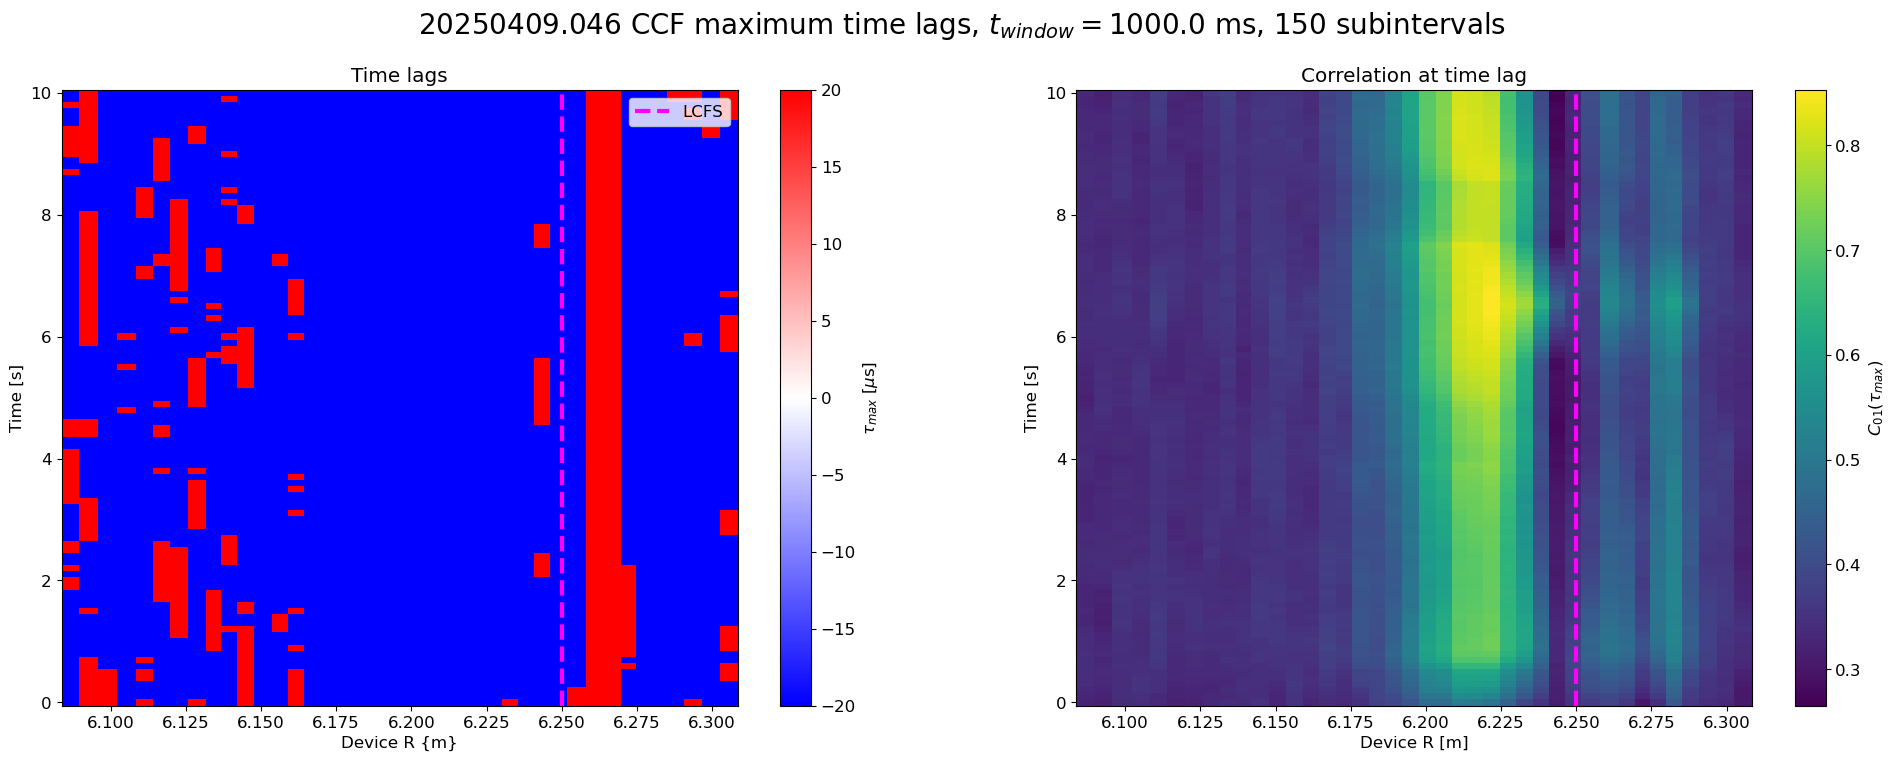

In [10]:
fig, ax = plt.subplots(figsize = (24, 8), nrows = 1, ncols = 2)
plt.suptitle(f'{exp_id} CCF maximum time lags, $t_{{window}} = {twindow*1e3}$ ms, {intervaln} subintervals', fontsize = 20)

ax[0].set_title('Time lags')
ax[0].set_xlabel('Device R {m}')
ax[0].set_ylabel('Time [s]')
pc1 = ax[0].pcolormesh(dev_r, times, tau, cmap = 'bwr', vmin = -20, vmax = 20, shading = 'nearest')
cbar1 = fig.colorbar(pc1, ax = ax[0])
cbar1.set_label('$\\tau_{max}$ [$\\mu$s]')

ax[0].axvline(r_lcfs, c = 'magenta', lw = 3, ls = '--', label = 'LCFS')
ax[1].axvline(r_lcfs, c = 'magenta', lw = 3, ls = '--')

ax[1].set_title('Correlation at time lag')
ax[1].set_xlabel('Device R [m]')
ax[1].set_ylabel('Time [s]')
pc2 = ax[1].pcolormesh(dev_r, times, corrs, cmap = 'viridis', shading = 'nearest')
cbar2 = fig.colorbar(pc2, ax = ax[1])
cbar2.set_label('$C_{01}(\\tau_{max})$')

ax[0].legend()
# plt.savefig(f'../plots/{exp_id}/longwindow/{exp_id}_ccf_corrs.pdf')

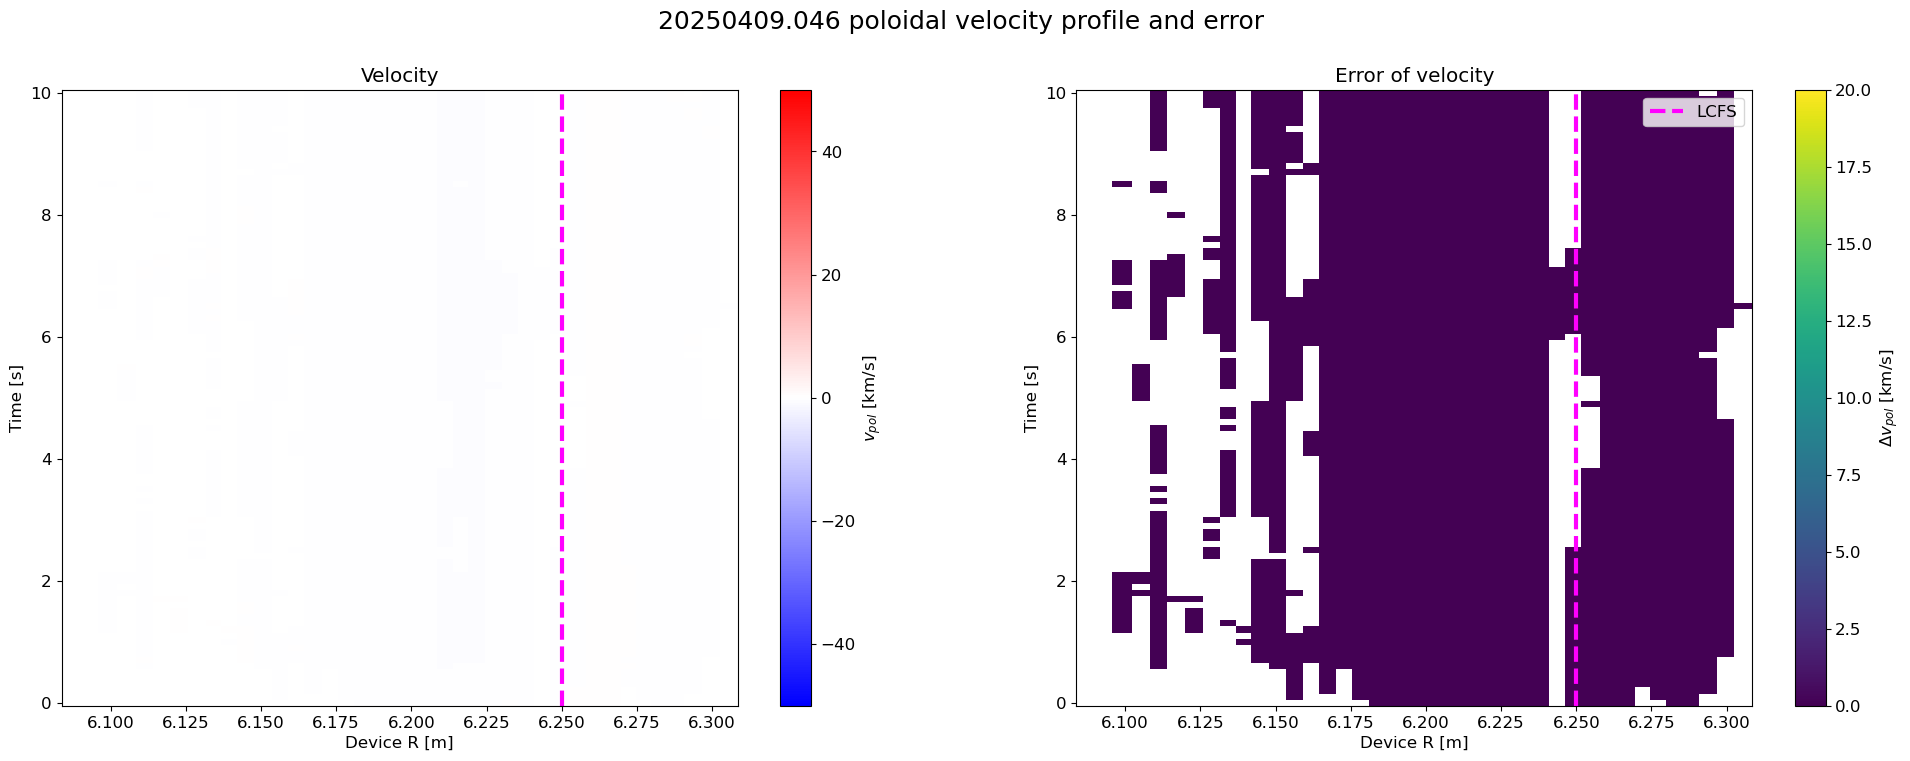

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (24, 8))
plt.suptitle(f'{exp_id} poloidal velocity profile and error', fontsize = 18)

ax1.set_title('Velocity')
ax1.set_xlabel('Device R [m]')
ax1.set_ylabel('Time [s]')
pc1 = ax1.pcolormesh(dev_r, times, vpol_filtered, cmap = 'bwr', vmin = -50, vmax = 50, shading = 'nearest')
cbar1 = fig.colorbar(pc1, ax = ax1)
cbar1.set_label('$v_{pol}$ [km/s]')

ax1.axvline(r_lcfs, lw = 3, c = 'magenta', ls = '--', label = 'LCFS')

ax2.set_title('Error of velocity')
ax2.set_xlabel('Device R [m]')
ax2.set_ylabel('Time [s]')
pc2 = ax2.pcolormesh(dev_r, times, vpol_err_filtered, cmap = 'viridis', vmin = 0, vmax = 20, shading = 'nearest')
cbar2 = fig.colorbar(pc2, ax = ax2)
cbar2.set_label('$\\Delta v_{pol}$ [km/s]')

ax2.axvline(r_lcfs, lw = 3, c = 'magenta', ls = '--', label = 'LCFS')

ax2.legend()
# plt.savefig(f'../plots/{exp_id}/longwindow/{exp_id}_vpol.pdf')

### Slice plots

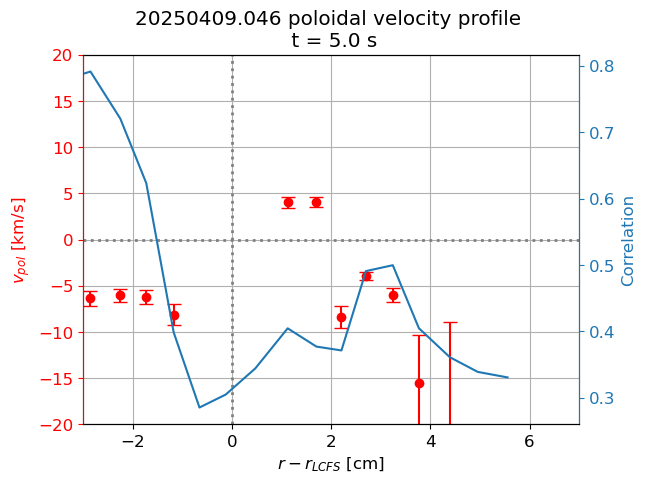

In [ ]:
fig, ax = plt.subplots()

ax.set_xlim(-3, 7)
ax.set_ylim(-20, 20)

ax2 = ax.twinx()

time_slice_idx = 50

ax.set_title(f'20250409.046 poloidal velocity profile \n t = {times[time_slice_idx]} s')

ax.set_ylabel('$v_{pol}$ [km/s]', color = 'red')
ax2.set_ylabel('Correlation', color = 'tab:blue')

ax.set_xlabel('$r - r_{LCFS}$ [cm]')

ax2.spines['left'].set_color('red')
ax2.spines['right'].set_color('tab:blue')

ax.tick_params(axis = 'y', colors = 'red')
ax2.tick_params(axis = 'y', colors = 'tab:blue')

mask = ~np.isnan(vpol_filtered[time_slice_idx])

ax.errorbar((dev_r[mask] - r_lcfs) * 100, vpol_filtered[time_slice_idx, mask], yerr = np.abs(vpol_err_filtered[time_slice_idx, mask]), capsize = 5, c = 'red', ls = 'none', marker = 'o')
ax2.plot((dev_r - r_lcfs) * 100, corrs[time_slice_idx], c = 'tab:blue')

ax.axvline(0, c = 'grey', ls = 'dotted', lw = 2)
ax.axhline(0, ls = 'dotted', c = 'grey', lw = 2)

ax.grid()
plt.savefig(f'../plots/{exp_id}/velocity_profile_spline_5s.pdf')

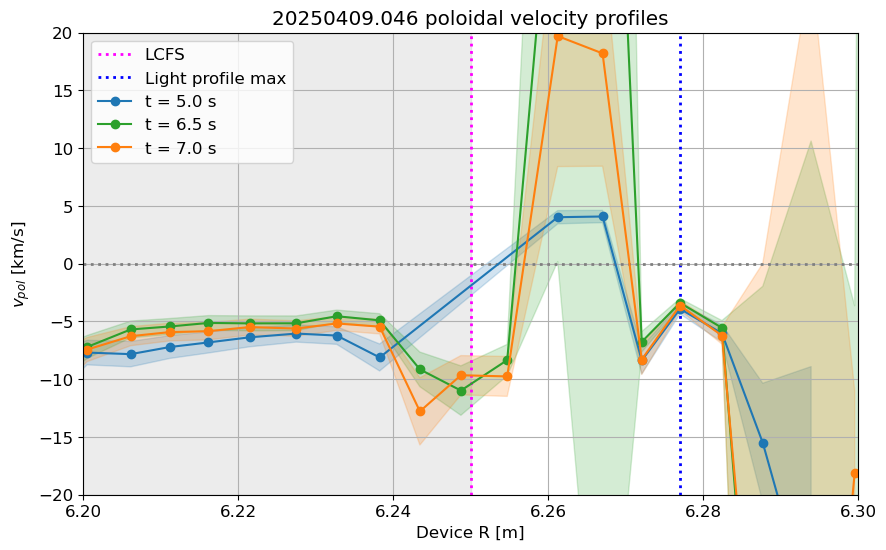

In [ ]:
fig, ax = plt.subplots(figsize = (10, 6))

ax.set_xlim(6.2, 6.3)
ax.set_ylim(-20, 20)

time_slices = [50, 65, 70]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']

ax.set_title(f'20250409.046 poloidal velocity profiles')

ax.set_ylabel('$v_{pol}$ [km/s]')
ax.set_xlabel('Device R [m]')
ax.axvline(r_lcfs, c = 'magenta', ls = 'dotted', lw = 2, label = 'LCFS')
ax.axvline(lightprof_max, c = 'blue', ls = 'dotted', lw = 2, label = 'Light profile max')
ax.axhline(0, lw = 2, ls = 'dotted', color = 'grey')

plt.fill_between([r_lcfs, r_lcfs - 0.1], -20, 20, color = 'grey', alpha = 0.15)

for (i, tidx) in enumerate(time_slices):

    mask = ~np.isnan(vpol_filtered[tidx])    
    ax.plot(dev_r[mask], vpol_filtered[tidx, mask], marker = 'o', label = f't = {times[tidx]} s', color = colors[i])
    ax.fill_between(dev_r[mask], vpol_filtered[tidx, mask] - np.abs(vpol_err_filtered[tidx, mask]), vpol_filtered[tidx, mask] + np.abs(vpol_err_filtered[tidx, mask]), color = colors[i], alpha = 0.2)

ax.grid()
ax.legend()
plt.savefig(f'../plots/{exp_id}/longwindow/velocity_profiles_tslice.pdf')

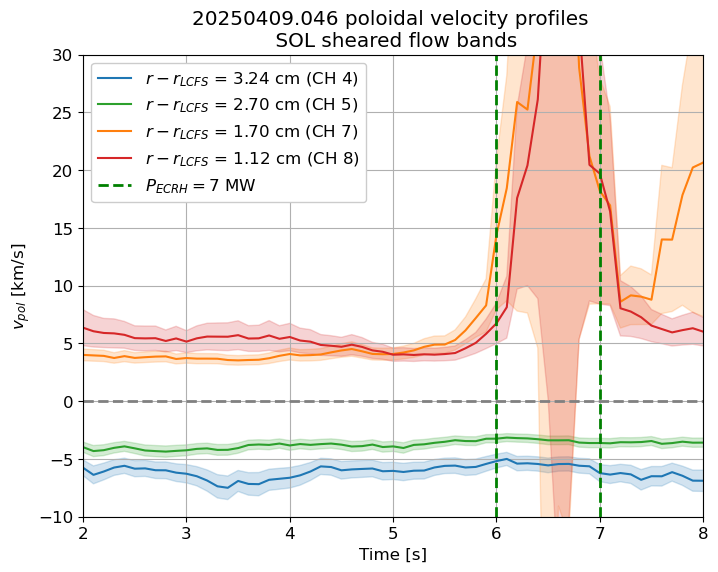

In [ ]:
fig, ax = plt.subplots(figsize = (8, 6))

channels = [5, 6, 8, 9]
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']

plt.xlim(2, 8)
plt.ylim(-10, 30)

ax.set_title(f'20250409.046 poloidal velocity profiles \n SOL sheared flow bands')

#ax.set_yticks(np.linspace(-12, 12, 13))
ax.set_ylabel('$v_{pol}$ [km/s]')
ax.set_xlabel('Time [s]')

for (i, ch) in enumerate(channels):
    
    chind = ch - 1

    ax.fill_between(times, vpol[:, chind] - vpol_err[:, chind], vpol[:, chind] + vpol_err[:, chind], color = colors[i], alpha = 0.2)
    ax.plot(times, vpol[:, chind], label = f'$r - r_{{LCFS}}$ = {((dev_r[chind] - r_lcfs)*100):.2f} cm (CH {chind})', color = colors[i])


ax.axhline(0, ls = '--', color = 'gray', lw = 2)

ax.axvline(6, c = 'green', ls = '--', lw = 2)
ax.axvline(7, c = 'green', ls = '--', lw = 2, label = '$P_{ECRH} = 7$ MW')

ax.grid()
ax.legend(framealpha = True)
# plt.savefig(f'../plots/{exp_id}/longwindow/{exp_id}_sol_shear_1.pdf')

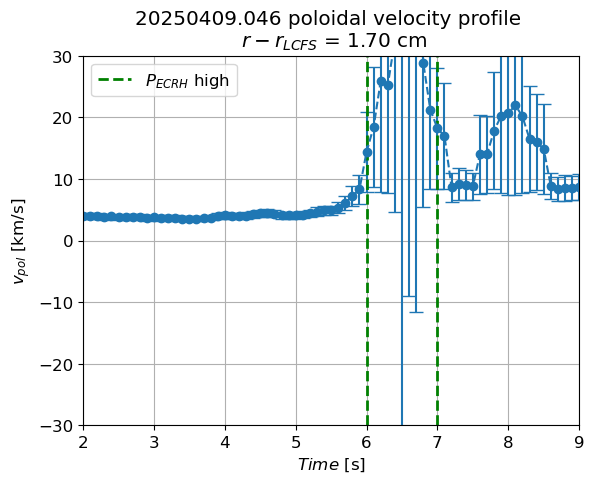

In [ ]:
fig, ax = plt.subplots()

ax.set_xlim(2, 9)
ax.set_ylim(-30, 30)

channel = 7

ax.set_title(f'{exp_id} poloidal velocity profile \n $r - r_{{LCFS}}$ = {((dev_r[channel] - r_lcfs) * 100):.2f} cm')

ax.set_ylabel('$v_{pol}$ [km/s]')

ax.set_xlabel('$Time$ [s]')

ax.errorbar(times, vpol[:, channel], yerr = vpol_err[:, channel], capsize = 5, ls = '--', marker = 'o')

ax.axvline(6, ls = '--', lw = 2, c = 'green', label = '$P_{ECRH}$ high')
ax.axvline(7, ls = '--', lw = 2, c = 'green')

ax.grid()
ax.legend()
plt.savefig(f'../plots/{exp_id}/longwindow/velocity_profile_timeseries.pdf')

### Light profile, electron density profile

In [ ]:
lightprof_path = ''
electron_dens_path = ''

flap_recon_path = os.path.abspath(f'/data2/W7-X/processed_data/APDCAM/flap_recon/{exp_id}')

for file in os.listdir(flap_recon_path):
    if re.search(r'light_ds_orig', file):
        lightprof_path = file
    elif re.search(r'dens', file):
        electron_dens_path = file
        
print('Matched recon data files:')
print(lightprof_path)
print(electron_dens_path)

lightprof = flap.load(os.path.join(flap_recon_path, lightprof_path))
electron_dens = flap.load(os.path.join(flap_recon_path, electron_dens_path))

lightprof_avg = lightprof.slice_data(
    slicing = {'Time': flap.Intervals(0, 10)},
    summing = {'Time': 'Mean'}
)

electron_dens_avg = electron_dens.slice_data(
    slicing = {'Time': flap.Intervals(0, 10)},
    summing = {'Time': 'Mean'}
)

Matched recon data files:
20250409.046_1.5500000000001624e-05-10.6199955_light_ds_orig_1774945808861.hdf5
20250409.046_1.5500000000001624e-05-10.6199955_dens_1774945808861.hdf5


In [ ]:
lightprof_max = lightprof_avg.coordinate('Device R')[0][np.argmax(lightprof_avg.data)]

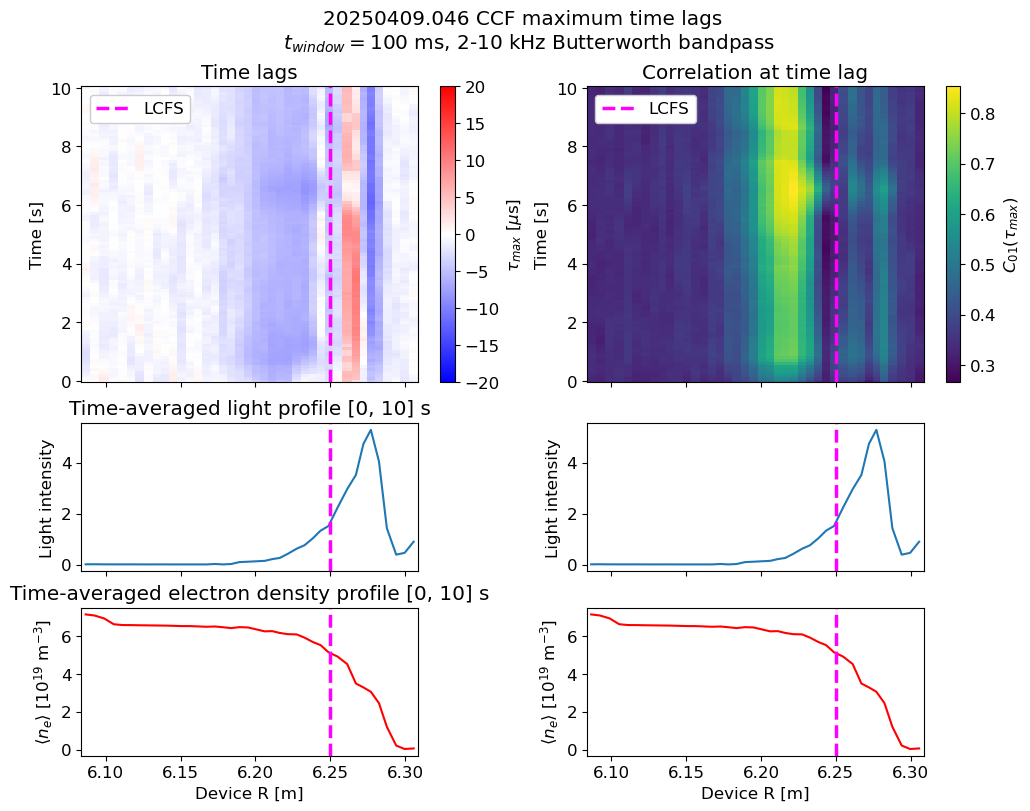

In [ ]:
fig, ax = plt.subplots(
    figsize = (10, 8),
    nrows = 3, ncols = 2,
    sharex = True,
    gridspec_kw = {'height_ratios':[2, 1, 1]},
    constrained_layout = True
)

plt.suptitle(f'{exp_id} CCF maximum time lags \n $t_{{window}} = 100$ ms, 2-10 kHz Butterworth bandpass')

ax[0, 0].set_title('Time lags')
ax[2, 0].set_xlabel('Device R [m]')
ax[2, 1].set_xlabel('Device R [m]')
ax[0, 0].set_ylabel('Time [s]')
pc1 = ax[0, 0].pcolormesh(dev_r, times, tau, cmap = 'bwr', vmin = -20, vmax = 20, shading = 'nearest')
cbar1 = fig.colorbar(pc1, ax = ax[0, 0])
cbar1.set_label('$\\tau_{max}$ [$\\mu$s]')

ax[0, 1].set_title('Correlation at time lag')
ax[0, 1].set_ylabel('Time [s]')
pc2 = ax[0, 1].pcolormesh(dev_r, times, corrs, cmap = 'viridis', shading = 'nearest')
cbar2 = fig.colorbar(pc2, ax = ax[0, 1])
cbar2.set_label('$C_{01}(\\tau_{max})$')

ax[1, 0].set_title('Time-averaged light profile [0, 10] s')
ax[1, 0].set_ylabel('Light intensity')
ax[1, 1].set_ylabel('Light intensity')

ax[1, 1].plot(lightprof_avg.coordinate('Device R')[0], lightprof_avg.data)
ax[1, 0].plot(lightprof_avg.coordinate('Device R')[0], lightprof_avg.data)

ax[2, 0].set_title('Time-averaged electron density profile [0, 10] s')
ax[2, 0].set_ylabel('$\\langle n_e \\rangle$ [$10^{19}$ m$^{-3}$]')
ax[2, 1].set_ylabel('$\\langle n_e \\rangle$ [$10^{19}$ m$^{-3}$]')

ax[2, 0].plot(electron_dens_avg.coordinate('Device R')[0], electron_dens_avg.data, c = 'r')
ax[2, 1].plot(electron_dens_avg.coordinate('Device R')[0], electron_dens_avg.data, c = 'r')

for axis in ax.flat:
    axis.axvline(r_lcfs, ls = '--', lw = 2.5, c = 'magenta', label = 'LCFS')

ax[0, 0].legend(framealpha = True)
ax[0, 1].legend(framealpha = True)
# plt.show()
plt.savefig(f'../plots/{exp_id}/longwindow/{exp_id}_ccf_light_dens_spline.pdf')

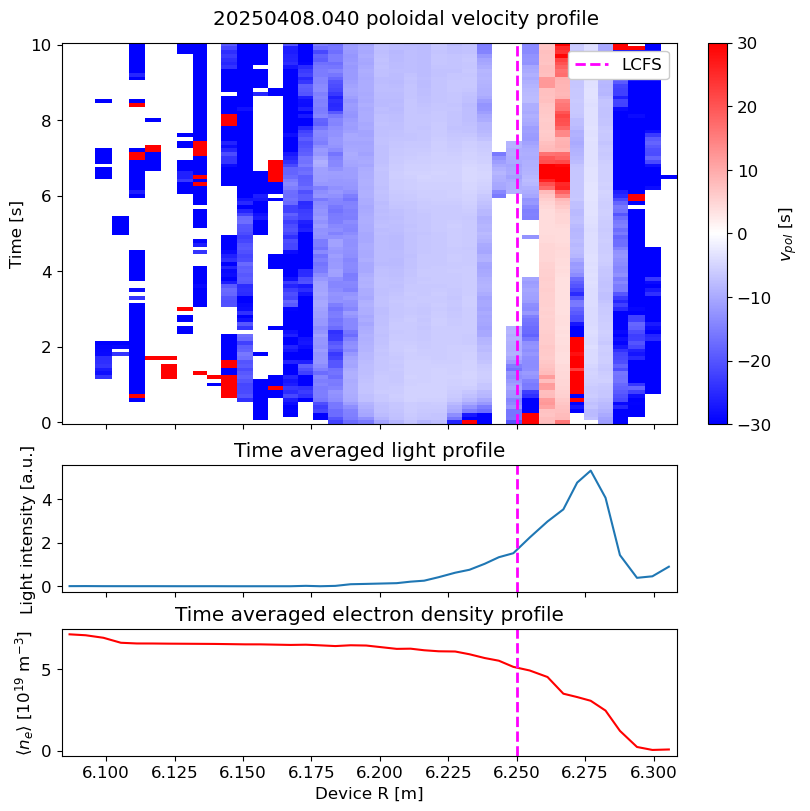

In [ ]:
fig, ax = plt.subplots(
    figsize = (8, 8),
    nrows = 3, ncols = 1,
    sharex = True,
    gridspec_kw = {'height_ratios':[3, 1, 1]},
    constrained_layout = True
)

plt.suptitle(f'20250408.040 poloidal velocity profile')

pcm = ax[0].pcolormesh(
    dev_r, times, vpol_filtered,
    cmap = 'bwr',
    vmin = -30, vmax = 30
)

ax[0].set_ylabel('Time [s]')
cbar = fig.colorbar(pcm, ax = ax[0])
cbar.set_label('$v_{pol}$ [s]')

ax[1].set_title('Time averaged light profile')
ax[1].set_ylabel('Light intensity [a.u.]')
ax[1].plot(lightprof_avg.coordinate('Device R')[0], lightprof_avg.data)

ax[2].set_title('Time averaged electron density profile')
ax[2].set_ylabel('$\\langle n_e \\rangle$ [$10^{19}$ m$^{-3}$]')
ax[2].plot(electron_dens_avg.coordinate('Device R')[0], electron_dens_avg.data, c = 'r')

ax[2].set_xlabel('Device R [m]')

for axis in ax:
    axis.axvline(r_lcfs, ls = '--', lw = 2, c = 'magenta', label = 'LCFS')

ax[0].legend(framealpha = True)

plt.savefig(f'../plots/{exp_id}/{exp_id}_vpol_light_dens_spline.pdf')

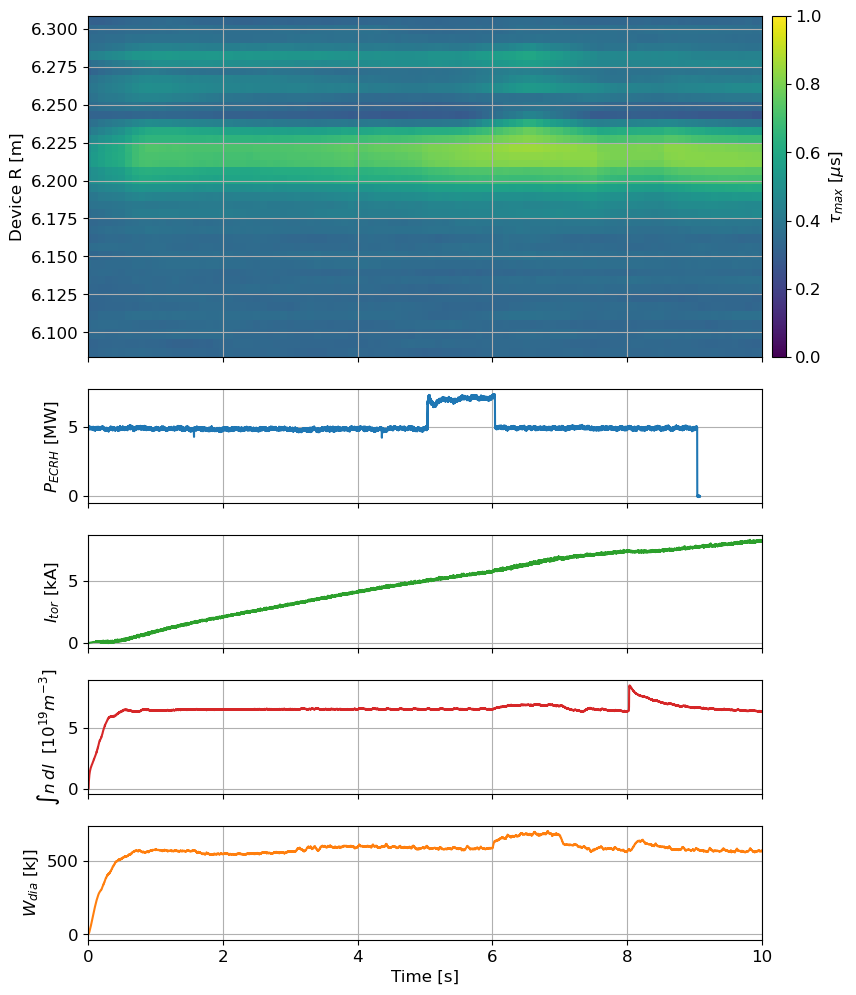

In [55]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, axes = plt.subplots(
    nrows = 5,
    ncols = 1,
    figsize = (9, 12),
    gridspec_kw={'height_ratios': [3, 1, 1, 1, 1]},
    sharex = True
)

pcm = axes[0].pcolormesh(times, dev_r, corrs.T, shading = 'nearest', vmin = 0, vmax = 1, cmap = 'viridis')
axes[0].set_ylabel('Device R [m]')

axes[1].plot(p_ecrh.coordinate('Time')[0], p_ecrh.data / 1e3)
axes[1].set_ylabel('$P_{ECRH}$ [MW]')

axes[2].plot(i_tor.coordinate('Time')[0], i_tor.data / 1e3, c = 'tab:green')
axes[2].set_ylabel('$I_{tor}$ [kA]')

axes[3].plot(n_int.coordinate('Time')[0], n_int.data, c = 'tab:red')
axes[3].set_ylabel('$\\int n \\: dl$  [$10^{19} m^{-3}$]')

axes[4].plot(w_dia.coordinate('Time')[0], w_dia.data, c = 'tab:orange')
axes[4].set_ylabel('$W_{dia}$ [kJ]')

axes[4].set_xlabel('Time [s]')

axes[4].set_xlim(0, 10)

for ax in axes: ax.grid()

# Reserve colorbar space on every panel so the shared x axes stay aligned
caxes = [make_axes_locatable(ax).append_axes('right', size = '2%', pad = 0.1) for ax in axes]
for cax in caxes[1:]: cax.set_axis_off()

cbar = fig.colorbar(pcm, cax = caxes[0])
cbar.set_label('$\\tau_{max}$ [$\\mu$s]')